# Havayolu Yolcularının Memnuniyet Düzeylerinin Tahmin Edilmesi

**Projenin amacı:** Bir yolcunun yaşı, seyahat tipi, uçuş sınıfı ve hizmetlere verdiği puanlar gibi bilgilere bakarak o yolcunun **memnun olup olmadığını tahmin eden** bir model kurmak.

**Makine öğrenmesi nedir?** Bilgisayara kuralları tek tek yazmak yerine çok sayıda örnek veriyoruz; bilgisayar bu örneklerdeki kalıpları kendisi öğreniyor ve yeni örnekler için tahmin yapıyor.

**Kullanılacak algoritmalar:** Karar Ağacı (Decision Tree) ve Rastgele Orman (Random Forest)

**Veri seti:** Kaggle – *Airline Passenger Satisfaction* (açık erişimli)
https://www.kaggle.com/datasets/teejmahal20/airline-passenger-satisfaction

## Adım 1: Veriyi Yükleme ve Tanıma

### 1.1 Kütüphaneleri içe aktarma
**Ne yapıyoruz?** Kullanacağımız hazır araçları (kütüphaneleri) projeye ekliyoruz.

**Neden?** Her şeyi sıfırdan yazmak yerine hazır araçları kullanıyoruz:
- **pandas:** Tabloları (Excel benzeri verileri) okumak ve işlemek için
- **numpy:** Sayısal hesaplamalar için
- **matplotlib / seaborn:** Grafik çizmek için

In [1]:
import pandas as pd               # tablo verileriyle çalışmak için
import numpy as np                # sayısal işlemler için
import matplotlib.pyplot as plt   # grafik çizmek için
import seaborn as sns             # daha güzel grafikler için

sns.set_theme(style="whitegrid")  # grafiklerin görünüm teması

### 1.2 Veri dosyalarını okuma
**Ne yapıyoruz?** `train.csv` ve `test.csv` dosyalarını okuyup birer tabloya (DataFrame) dönüştürüyoruz.

**Neden iki ayrı dosya var?**
- **Eğitim verisi (train):** Modelin öğrenmek için kullandığı örnekler. Öğrencinin çalıştığı ders kitabı gibi düşünebilirsin.
- **Test verisi (test):** Modelin daha önce hiç görmediği örnekler. Sınav soruları gibi; modelin gerçekten öğrenip öğrenmediğini bunlarla ölçeceğiz.

In [2]:
train = pd.read_csv("data/train.csv")   # eğitim verisi
test = pd.read_csv("data/test.csv")     # test verisi

# shape -> (satır sayısı, sütun sayısı)
print("Eğitim verisi boyutu:", train.shape)
print("Test verisi boyutu  :", test.shape)

Eğitim verisi boyutu: (103904, 25)
Test verisi boyutu  : (25976, 25)


### 1.3 İlk satırlara göz atma
**Ne yapıyoruz?** Tablonun ilk 5 satırını gösteriyoruz.

**Neden?** Verinin neye benzediğini görmek için. Her **satır** bir yolcuyu, her **sütun** o yolcuya ait bir bilgiyi gösterir.

In [3]:
train.head()   # ilk 5 satırı göster

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


### 1.4 Sütunların açıklaması
Veri setinde 25 sütun var. Bunları gruplara ayırırsak:

| Grup | Sütunlar | Açıklama |
|---|---|---|
| Gereksiz | `Unnamed: 0`, `id` | Sadece sıra numarası; tahmine katkısı yok |
| Yolcu bilgisi | `Gender`, `Age`, `Customer Type` | Cinsiyet, yaş, sadık müşteri mi değil mi |
| Uçuş bilgisi | `Type of Travel`, `Class`, `Flight Distance` | İş/kişisel seyahat, Business/Eco/Eco Plus sınıfı, uçuş mesafesi |
| Gecikmeler | `Departure Delay in Minutes`, `Arrival Delay in Minutes` | Kalkış ve varış gecikmesi (dakika) |
| Hizmet puanları | `Inflight wifi service`, `Online boarding`, `Seat comfort`, `Cleanliness` vb. 14 sütun | Yolcunun hizmetlere verdiği puan (1–5; 0 = puan verilmemiş) |
| **Hedef** | `satisfaction` | **Tahmin etmek istediğimiz sütun:** *satisfied* (memnun) veya *neutral or dissatisfied* (nötr ya da memnun değil) |

**Hedef değişken (target):** Modelin tahmin etmeye çalıştığı sütundur. Diğer sütunlara **özellik (feature)** denir; model bu özelliklere bakarak hedefi tahmin eder.

Hedefimiz iki seçenekten birini tahmin etmek olduğu için bu bir **sınıflandırma (classification)** problemidir. (Fiyat gibi bir sayı tahmin etseydik buna *regresyon* denirdi.)

### 1.5 Sütun tipleri
**Ne yapıyoruz?** Her sütunun tipine ve kaç tane dolu değeri olduğuna bakıyoruz.

**Neden?** Model yalnızca **sayılarla** çalışabilir. Hangi sütunların yazı (object) olduğunu bilirsek, bunları ileride sayıya çevirmemiz gerektiğini anlarız. Ayrıca dolu değer sayısı 103.904'ten az olan bir sütunda **eksik veri** olduğunu da buradan görebiliriz.

In [4]:
train.info()   # sütun adları, dolu değer sayıları ve veri tipleri

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Unnamed: 0                         103904 non-null  int64  
 1   id                                 103904 non-null  int64  
 2   Gender                             103904 non-null  object 
 3   Customer Type                      103904 non-null  object 
 4   Age                                103904 non-null  int64  
 5   Type of Travel                     103904 non-null  object 
 6   Class                              103904 non-null  object 
 7   Flight Distance                    103904 non-null  int64  
 8   Inflight wifi service              103904 non-null  int64  
 9   Departure/Arrival time convenient  103904 non-null  int64  
 10  Ease of Online booking             103904 non-null  int64  
 11  Gate location                      1039

**Ne görüyoruz?**
- `int64` / `float64` sütunlar sayısaldır; `object` sütunlar yazıdır: Gender, Customer Type, Type of Travel, Class, satisfaction
- `Arrival Delay in Minutes` sütununda 103.904 yerine 103.594 dolu değer var, yani **310 eksik değer** var. Bunu ön işleme adımında düzelteceğiz.

### 1.6 Sayısal sütunların özet istatistikleri
**Ne yapıyoruz?** Her sayısal sütunun ortalamasına, en küçük ve en büyük değerine bakıyoruz.

**Neden?** Uç ve tuhaf değerleri yakalamak ve verinin genel resmini görmek için.
(`mean` = ortalama, `std` = değerlerin ortalamadan ne kadar saptığı, `min`/`max` = en küçük ve en büyük değer, `50%` = medyan, yani sıralamada tam ortadaki değer)

In [5]:
# 'Unnamed: 0' ve 'id' sadece sıra numarası olduğu için özete katmıyoruz
train.drop(columns=["Unnamed: 0", "id"]).describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Age,103904.0,39.4,15.1,7.0,27.0,40.0,51.0,85.0
Flight Distance,103904.0,1189.4,997.1,31.0,414.0,843.0,1743.0,4983.0
Inflight wifi service,103904.0,2.7,1.3,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,103904.0,3.1,1.5,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,103904.0,2.8,1.4,0.0,2.0,3.0,4.0,5.0
Gate location,103904.0,3.0,1.3,0.0,2.0,3.0,4.0,5.0
Food and drink,103904.0,3.2,1.3,0.0,2.0,3.0,4.0,5.0
Online boarding,103904.0,3.3,1.3,0.0,2.0,3.0,4.0,5.0
Seat comfort,103904.0,3.4,1.3,0.0,2.0,4.0,5.0,5.0
Inflight entertainment,103904.0,3.4,1.3,0.0,2.0,4.0,4.0,5.0


**Ne görüyoruz?**
- Yolcuların yaşı 7 ile 85 arasında, ortalaması yaklaşık 39.
- Uçuş mesafesi 31 ile yaklaşık 5.000 arasında değişiyor (veri setinde birim belirtilmemiş, büyük ihtimalle mil).
- Gecikmelerin medyanı 0, yani yolcuların çoğu gecikme yaşamamış. Ama en büyük değer yaklaşık 1.600 dakika; birkaç çok uzun gecikme var.
- Hizmet puanları 0 ile 5 arasında.

## Adım 2: Temel Analiz ve Grafikler (Keşifsel Veri Analizi)

Bu adıma **Keşifsel Veri Analizi** (İngilizcesi *Exploratory Data Analysis*, kısaca **EDA**) denir: Model kurmadan önce veriyi grafiklerle inceleyip "memnuniyeti neler etkiliyor olabilir?" sorusuna ilk ipuçlarını ararız.

Grafiklerde hep aynı renkleri kullanacağız: **kırmızı = memnun değil/nötr**, **yeşil = memnun**.

In [6]:
# Grafiklerde kullanacağımız renkler: kırmızı = memnun değil, yeşil = memnun
renkler = ["#d9534f", "#5cb85c"]

### 2.1 Memnun ve memnun olmayan yolcuların sayısı
**Ne yapıyoruz?** Hedef değişkendeki iki grubun kaçar kişi olduğunu sayıyoruz.

**Neden?** İki grup arasında çok büyük bir fark varsa (örneğin %95'e %5), veri **dengesiz** (*imbalanced*) demektir. Böyle bir veride model her yolcuya "memnun değil" deyip yine de %95 doğru çıkabilir, yani bizi yanıltabilir. Önce bunu kontrol ediyoruz.

satisfaction
neutral or dissatisfied    58879
satisfied                  45025
Name: count, dtype: int64

satisfaction
neutral or dissatisfied    56.7
satisfied                  43.3
Name: proportion, dtype: float64


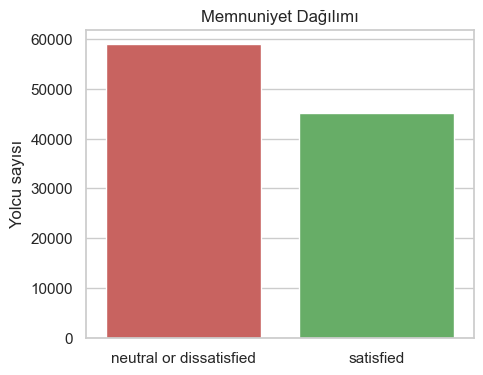

In [7]:
# Her gruptan kaç yolcu var ve bu yüzde kaç ediyor?
print(train["satisfaction"].value_counts())
print()
print((train["satisfaction"].value_counts(normalize=True) * 100).round(1))

# Sütun grafiği
plt.figure(figsize=(5, 4))
sns.countplot(data=train, x="satisfaction", palette=renkler)
plt.title("Memnuniyet Dağılımı")
plt.xlabel("")
plt.ylabel("Yolcu sayısı")
plt.show()

**Ne görüyoruz?** Yolcuların yaklaşık **%57'si memnun değil/nötr**, **%43'ü memnun**. İki grubun büyüklüğü birbirine oldukça yakın, yani veri **dengeli** sayılır. Bu iyi bir haber: Özel bir düzeltme yapmamıza gerek yok.

### 2.2 Uçuş sınıfı ve memnuniyet
**Ne yapıyoruz?** Business, Eco ve Eco Plus sınıflarının her birinde yolcuların yüzde kaçının memnun olduğuna bakıyoruz.

**Neden?** Bir özellik ile memnuniyet arasında güçlü bir ilişki varsa, o özellik modelin tahmin yapmasında işe yarayacaktır.

`pd.crosstab` iki sütunu çapraz tablo halinde karşılaştırır. `normalize="index"` seçeneği sayılar yerine her satırın kendi içindeki yüzdesini verir.

satisfaction  neutral or dissatisfied  satisfied
Class                                           
Business                         30.6       69.4
Eco                              81.4       18.6
Eco Plus                         75.4       24.6


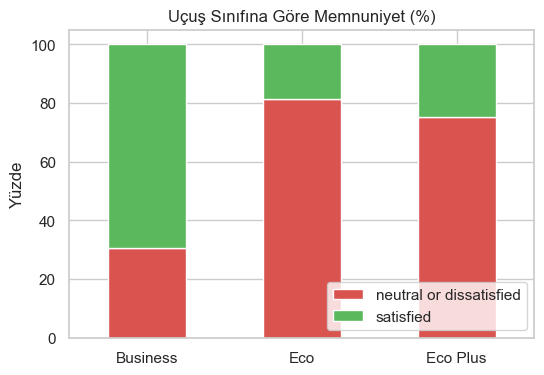

In [8]:
# Her sınıfta memnun / memnun değil oranı (%)
sinif_tablo = pd.crosstab(train["Class"], train["satisfaction"], normalize="index") * 100
print(sinif_tablo.round(1))

# Yığılmış (üst üste) sütun grafiği
sinif_tablo.plot(kind="bar", stacked=True, color=renkler, figsize=(6, 4))
plt.title("Uçuş Sınıfına Göre Memnuniyet (%)")
plt.xlabel("")
plt.ylabel("Yüzde")
plt.xticks(rotation=0)
plt.legend(title="", loc="lower right")
plt.show()

**Ne görüyoruz?** **Business** sınıfında yolcuların yaklaşık **%69'u memnun**, **Eco** sınıfında ise yalnızca **%19'u**. Uçuş sınıfı memnuniyeti çok güçlü biçimde etkiliyor.

### 2.3 Seyahat tipi, müşteri tipi ve cinsiyet
**Ne yapıyoruz?** Aynı karşılaştırmayı üç sütun için daha yapıyoruz. Kodu üç kere yazmamak için bir **döngü** (`for`) kullanıyoruz. Döngü, aynı işi listedeki her eleman için sırayla tekrarlar.

satisfaction     neutral or dissatisfied  satisfied
Type of Travel                                     
Business travel                     41.7       58.3
Personal Travel                     89.8       10.2 

satisfaction       neutral or dissatisfied  satisfied
Customer Type                                        
Loyal Customer                        52.3       47.7
disloyal Customer                     76.3       23.7 

satisfaction  neutral or dissatisfied  satisfied
Gender                                          
Female                           57.3       42.7
Male                             56.1       43.9 



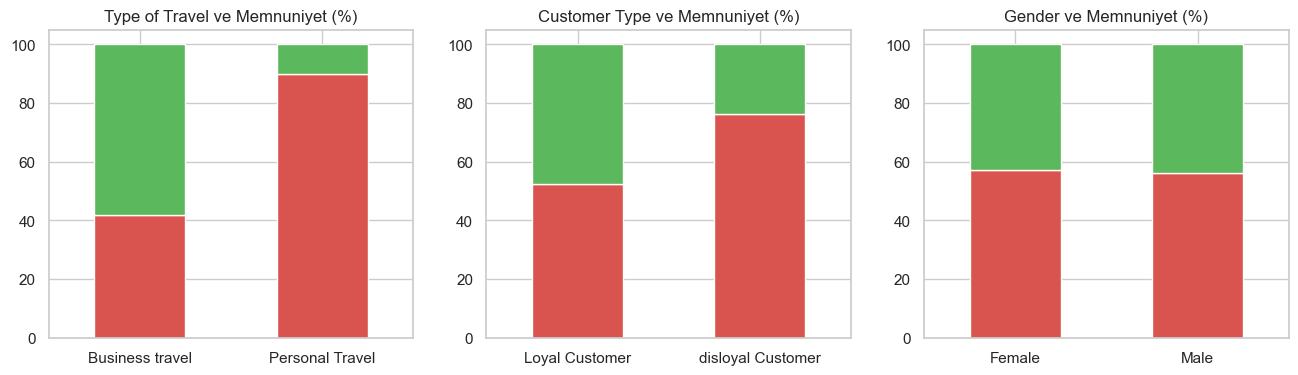

In [9]:
sutunlar = ["Type of Travel", "Customer Type", "Gender"]

# 1 satır, 3 sütunluk bir grafik alanı oluştur
fig, eksenler = plt.subplots(1, 3, figsize=(16, 4))

for eksen, sutun in zip(eksenler, sutunlar):
    tablo = pd.crosstab(train[sutun], train["satisfaction"], normalize="index") * 100
    print(tablo.round(1), "\n")
    tablo.plot(kind="bar", stacked=True, color=renkler, ax=eksen, legend=False)
    eksen.set_title(f"{sutun} ve Memnuniyet (%)")
    eksen.set_xlabel("")
    eksen.tick_params(axis="x", rotation=0)

plt.show()

**Ne görüyoruz?**
- **Seyahat tipi:** İş amaçlı seyahat edenlerin **%58'i** memnun. Kişisel seyahat edenlerde bu oran yalnızca **%10**. Çok güçlü bir etki.
- **Müşteri tipi:** Sadık müşterilerin **%48'i**, sadık olmayanların **%24'ü** memnun.
- **Cinsiyet:** Kadın ve erkeklerde oranlar neredeyse aynı (%43 ve %44). Cinsiyetin memnuniyete **etkisi yok** gibi görünüyor.

### 2.4 Yaş ve memnuniyet
**Ne yapıyoruz?** Yaş için bir **histogram** çiziyoruz. Histogram, sayısal bir değişkeni aralıklara bölüp her aralıkta kaç kişi olduğunu gösteren grafiktir.

**Neden?** Yaş bir kategori değil, sayı olduğu için sütun grafiği yerine histogram kullanıyoruz.

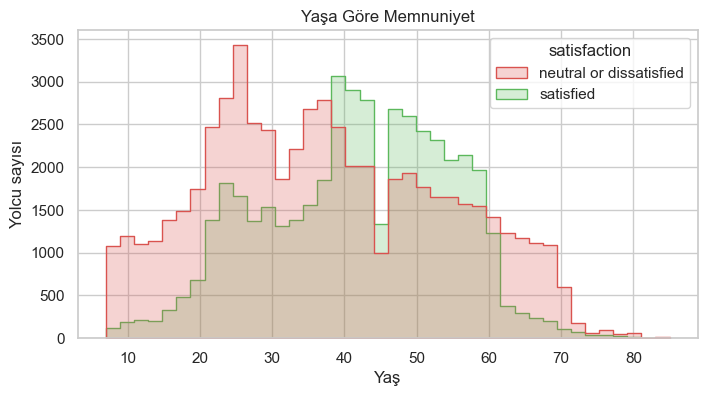

In [10]:
plt.figure(figsize=(8, 4))
sns.histplot(data=train, x="Age", hue="satisfaction", bins=40, palette=renkler, element="step")
plt.title("Yaşa Göre Memnuniyet")
plt.xlabel("Yaş")
plt.ylabel("Yolcu sayısı")
plt.show()

**Ne görüyoruz?** **40–60 yaş** arasındaki yolcularda yeşil (memnun) çizgi kırmızının üstüne çıkıyor; bu yaş grubunun yaklaşık **%57'si** memnun. **20 yaş altındaki** ve **60 yaş üstündeki** yolcularda ise memnuniyet oranı yalnızca **%20** civarında.

### 2.5 Hizmet puanları ve memnuniyet
**Ne yapıyoruz?** 14 hizmetin her biri için, memnun ve memnun olmayan yolcuların verdiği **ortalama puanı** karşılaştırıyoruz.

**Neden?** İki grubun puanları arasındaki fark ne kadar büyükse, o hizmet memnuniyet üzerinde o kadar etkili demektir.

satisfaction                       neutral or dissatisfied  satisfied
Departure/Arrival time convenient                     3.13       2.97
Gate location                                         2.98       2.98
Ease of Online booking                                2.55       3.03
Inflight wifi service                                 2.40       3.16
Food and drink                                        2.96       3.52
Checkin service                                       3.04       3.65
Cleanliness                                           2.94       3.74
Leg room service                                      2.99       3.82
On-board service                                      3.02       3.86
Inflight entertainment                                2.89       3.96
Baggage handling                                      3.38       3.97
Seat comfort                                          3.04       3.97
Inflight service                                      3.39       3.97
Online boarding     

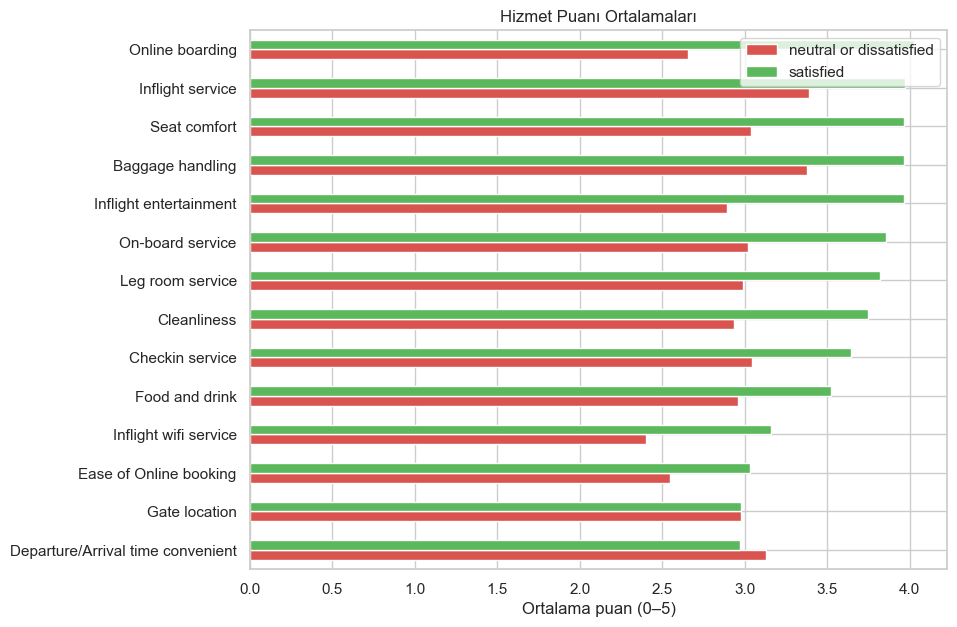

In [11]:
# Hizmet puanı sütunları
hizmetler = ["Inflight wifi service", "Departure/Arrival time convenient", "Ease of Online booking",
             "Gate location", "Food and drink", "Online boarding", "Seat comfort",
             "Inflight entertainment", "On-board service", "Leg room service",
             "Baggage handling", "Checkin service", "Inflight service", "Cleanliness"]

# Her grubun her hizmete verdiği ortalama puan
ortalamalar = train.groupby("satisfaction")[hizmetler].mean().T
ortalamalar = ortalamalar.sort_values("satisfied")   # grafikte sıralı görünsün
print(ortalamalar.round(2))

ortalamalar.plot(kind="barh", color=renkler, figsize=(9, 7))
plt.title("Hizmet Puanı Ortalamaları")
plt.xlabel("Ortalama puan (0–5)")
plt.legend(title="")
plt.show()

**Ne görüyoruz?**
- En büyük fark **Online boarding** (çevrimiçi biniş) hizmetinde: Memnun yolcular ortalama **4,0**, memnun olmayanlar **2,7** puan vermiş.
- Ardından **Inflight entertainment** (uçak içi eğlence) ve **Seat comfort** (koltuk konforu) geliyor.
- **Gate location** (kapı konumu) ve **Departure/Arrival time convenient** (kalkış/varış saatinin uygunluğu) hizmetlerinde iki grup arasında neredeyse fark yok. Bu hizmetler memnuniyeti pek etkilemiyor.

### 2.6 Korelasyon: Hangi sayısal özellik memnuniyetle birlikte değişiyor?
**Korelasyon**, iki değişkenin birlikte ne kadar değiştiğini gösteren, -1 ile +1 arasında bir sayıdır:
- **+1'e yakın:** Biri artınca öteki de artar.
- **-1'e yakın:** Biri artınca öteki azalır.
- **0'a yakın:** Aralarında belirgin bir ilişki yok.

**Ne yapıyoruz?** Hedefi geçici olarak sayıya çeviriyoruz (memnun = 1, memnun değil = 0). Sonra her sayısal sütunun bu hedefle korelasyonunu hesaplıyoruz.

Arrival Delay in Minutes            -0.058
Departure/Arrival time convenient   -0.052
Departure Delay in Minutes          -0.050
Gate location                        0.001
Age                                  0.137
Ease of Online booking               0.172
Food and drink                       0.210
Checkin service                      0.236
Inflight service                     0.245
Baggage handling                     0.248
Inflight wifi service                0.284
Flight Distance                      0.299
Cleanliness                          0.305
Leg room service                     0.313
On-board service                     0.322
Seat comfort                         0.349
Inflight entertainment               0.398
Online boarding                      0.504
dtype: float64


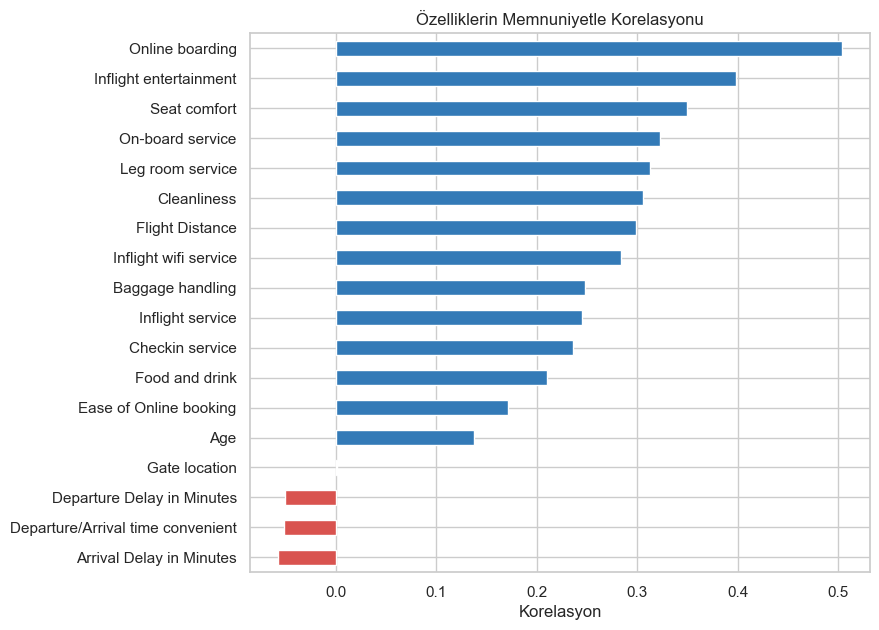

In [12]:
# Hedefi geçici olarak 0/1 sayısına çevir (asıl dönüşümü ön işleme adımında yapacağız)
hedef_sayi = (train["satisfaction"] == "satisfied").astype(int)

# Sadece sayısal sütunları al (sıra numarası sütunları hariç)
sayisal = train.drop(columns=["Unnamed: 0", "id"]).select_dtypes("number")

# Her sütunun hedefle korelasyonu
korelasyon = sayisal.corrwith(hedef_sayi).sort_values()
print(korelasyon.round(3))

korelasyon.plot(kind="barh", figsize=(8, 7), color=["#d9534f" if k < 0 else "#337ab7" for k in korelasyon])
plt.title("Özelliklerin Memnuniyetle Korelasyonu")
plt.xlabel("Korelasyon")
plt.show()

**Ne görüyoruz?**
- Memnuniyetle en güçlü ilişkiye sahip özellik **Online boarding** (0,50). Onu **Inflight entertainment** (0,40) ve **Seat comfort** (0,35) izliyor.
- **Gecikme** sütunları hafif negatif (yaklaşık -0,05): Gecikme arttıkça memnuniyet biraz azalıyor, ama etki zayıf.
- **Gate location** neredeyse 0: Memnuniyetle ilişkisi yok.

**Not:** Korelasyon yalnızca **doğrusal** (düz bir çizgi gibi) ilişkileri ölçer. Karar ağaçları daha karmaşık ilişkileri de yakalayabilir; bu yüzden düşük korelasyonlu özellikleri hemen atmıyoruz.

### Adım 2 Özeti
Grafiklere göre memnuniyeti en çok etkileyen özellikler:
1. **Seyahat tipi** (iş seyahati yapanlar çok daha memnun)
2. **Uçuş sınıfı** (Business sınıfı yolcular çok daha memnun)
3. **Online boarding, uçak içi eğlence ve koltuk konforu** puanları

Cinsiyetin ve kapı konumunun ise etkisi neredeyse yok. Model kurulduktan sonra bu tahminlerimizin doğru çıkıp çıkmadığını **özellik önem düzeyleri** (feature importance) ile kontrol edeceğiz.

## Adım 3: Veri Ön İşleme

**Veri ön işleme** (*data preprocessing*), ham veriyi modelin kullanabileceği hale getirmektir. Model, eksik değer içeren ya da yazı halindeki sütunlarla çalışamaz. Bu yüzden şu işleri yapacağız:
1. Gereksiz sütunları atmak
2. Eksik değerleri doldurmak
3. Yazı halindeki sütunları sayıya çevirmek (**encoding**)
4. Veriyi özellikler (X) ve hedef (y) olarak ikiye ayırmak

**Önemli kural:** Eğitim verisine ne yaptıysak test verisine de **aynısını** yapmalıyız. Yoksa model sınavda (test) ders kitabındakinden (train) farklı biçimde yazılmış sorularla karşılaşır.

Orijinal tabloları bozmamak için önce birer kopya alıyoruz.

In [13]:
# Orijinal veriyi bozmamak için kopyalarını alıyoruz
train_hazir = train.copy()
test_hazir = test.copy()

### 3.1 Gereksiz sütunları atma
**Ne yapıyoruz?** `Unnamed: 0` ve `id` sütunlarını siliyoruz.

**Neden?** Bunlar yalnızca sıra numarası; yolcunun memnuniyeti hakkında hiçbir bilgi taşımıyorlar. Modelde kalırlarsa model bu anlamsız sayılardan sahte kalıplar öğrenmeye çalışabilir.

In [14]:
gereksiz = ["Unnamed: 0", "id"]
train_hazir = train_hazir.drop(columns=gereksiz)
test_hazir = test_hazir.drop(columns=gereksiz)

print("Yeni boyutlar:", train_hazir.shape, test_hazir.shape)

Yeni boyutlar: (103904, 23) (25976, 23)


### 3.2 Eksik değerleri doldurma
**Eksik değer** (*missing value*), tabloda boş kalmış bir hücredir. Python'da `NaN` olarak görünür.

**Ne yapıyoruz?** Önce hangi sütunda kaç eksik değer olduğunu sayıyoruz.

In [15]:
print("Eğitim verisindeki eksik değerler:")
print(train_hazir.isnull().sum()[train_hazir.isnull().sum() > 0])   # sadece eksiği olan sütunlar

print("\nTest verisindeki eksik değerler:")
print(test_hazir.isnull().sum()[test_hazir.isnull().sum() > 0])

Eğitim verisindeki eksik değerler:
Arrival Delay in Minutes    310
dtype: int64

Test verisindeki eksik değerler:
Arrival Delay in Minutes    83
dtype: int64


Yalnızca `Arrival Delay in Minutes` (varış gecikmesi) sütununda eksik değer var: Eğitim verisinde 310, test verisinde 83 satır. Bu, verinin yalnızca **%0,3'ü** kadar.

**Ne yapıyoruz?** Boş hücreleri bu sütunun **medyanı** ile dolduruyoruz.

**Neden ortalama değil de medyan?** Bu sütunda 1.500 dakikayı aşan birkaç uç değer var. **Ortalama** bu uç değerlerden çok etkilenir ve yukarı kayar. **Medyan** ise sıralamada tam ortadaki değerdir ve uç değerlerden etkilenmez.

**Neden test verisini de eğitim verisinin medyanıyla dolduruyoruz?** Test verisi, modelin hiç görmediği "gelecekteki" veriyi temsil eder. Test verisinden herhangi bir bilgi kullanırsak modelin sınav sorularını önceden görmesi gibi olur. Bu hataya **veri sızıntısı** (*data leakage*) denir.

In [16]:
# Medyanı sadece eğitim verisinden hesaplıyoruz
medyan = train_hazir["Arrival Delay in Minutes"].median()
print("Varış gecikmesi medyanı:", medyan, "dakika")

# Boş hücreleri bu medyan ile dolduruyoruz (hem eğitim hem test)
train_hazir["Arrival Delay in Minutes"] = train_hazir["Arrival Delay in Minutes"].fillna(medyan)
test_hazir["Arrival Delay in Minutes"] = test_hazir["Arrival Delay in Minutes"].fillna(medyan)

# Kontrol: artık hiç eksik değer kalmamalı
print("Kalan eksik değer (eğitim):", train_hazir.isnull().sum().sum())
print("Kalan eksik değer (test):", test_hazir.isnull().sum().sum())

Varış gecikmesi medyanı: 0.0 dakika
Kalan eksik değer (eğitim): 0
Kalan eksik değer (test): 0


**Ne görüyoruz?** Medyan **0 dakika**, çünkü yolcuların yarısından fazlası hiç gecikme yaşamamış. Boş hücreler "gecikme yok" anlamına gelen 0 ile doldu. Artık veride eksik değer kalmadı.

### 3.3 Encoding: Yazıları sayıya çevirme
**Encoding** (kodlama), yazı halindeki kategorileri modelin anlayabileceği sayılara çevirmektir. Makine öğrenmesi modelleri yalnızca sayılarla hesap yapabilir; "Male" ya da "Business" gibi yazıları anlayamaz.

Önce hangi sütunların yazı olduğuna ve içlerinde hangi değerler bulunduğuna bakalım:

In [17]:
yazi_sutunlari = train_hazir.select_dtypes("object").columns   # tipi yazı (object) olan sütunlar

for sutun in yazi_sutunlari:
    print(sutun, "->", train_hazir[sutun].unique())   # sütundaki farklı değerler

Gender -> ['Male' 'Female']
Customer Type -> ['Loyal Customer' 'disloyal Customer']
Type of Travel -> ['Personal Travel' 'Business travel']
Class -> ['Eco Plus' 'Business' 'Eco']
satisfaction -> ['neutral or dissatisfied' 'satisfied']


#### a) İki seçenekli sütunlar → 0 / 1
`Gender`, `Customer Type` ve `Type of Travel` sütunlarının her birinde yalnızca **iki** seçenek var. Bunları basitçe 0 ve 1'e çeviriyoruz:

| Sütun | 1 olacak değer | 0 olacak değer |
|---|---|---|
| Gender | Male | Female |
| Customer Type | Loyal Customer | disloyal Customer |
| Type of Travel | Business travel | Personal Travel |

`(sütun == "değer")` ifadesi her satır için True ya da False üretir. `.astype(int)` bunu True → 1, False → 0 olarak sayıya çevirir.

In [18]:
for veri in [train_hazir, test_hazir]:   # aynı işlemi iki tabloya da uygula
    veri["Gender"] = (veri["Gender"] == "Male").astype(int)
    veri["Customer Type"] = (veri["Customer Type"] == "Loyal Customer").astype(int)
    veri["Type of Travel"] = (veri["Type of Travel"] == "Business travel").astype(int)

train_hazir[["Gender", "Customer Type", "Type of Travel"]].head()

,Gender,Customer Type,Type of Travel
0,1,1,0
1,1,0,1
2,0,1,1
3,0,1,1
4,1,1,1


#### b) Üç seçenekli sütun → One-Hot Encoding
`Class` sütununda **üç** seçenek var: Business, Eco, Eco Plus.

Bunları doğrudan 0, 1, 2 diye numaralandırsaydık, model bu sayıları **büyüklük** olarak yorumlayabilir ve "Eco Plus (2), Eco'nun (1) iki katıdır" gibi anlamsız bir sonuca varabilirdi.

Bunun yerine **One-Hot Encoding** kullanıyoruz: Her seçenek için ayrı bir sütun açıyoruz. Yolcu o sınıftaysa sütuna 1, değilse 0 yazıyoruz.

| Class | → | Class_Business | Class_Eco | Class_Eco Plus |
|---|---|---|---|---|
| Business | | 1 | 0 | 0 |
| Eco | | 0 | 1 | 0 |
| Eco Plus | | 0 | 0 | 1 |

`pd.get_dummies` bu işi otomatik yapar.

In [19]:
train_hazir = pd.get_dummies(train_hazir, columns=["Class"], dtype=int)
test_hazir = pd.get_dummies(test_hazir, columns=["Class"], dtype=int)

train_hazir.filter(like="Class").head()   # adında 'Class' geçen yeni sütunları göster

,Class_Business,Class_Eco,Class_Eco Plus
0,0,0,1
1,1,0,0
2,1,0,0
3,1,0,0
4,1,0,0


#### c) Hedef değişken → 0 / 1
Son olarak tahmin edeceğimiz `satisfaction` sütununu da sayıya çeviriyoruz: **satisfied (memnun) = 1**, **neutral or dissatisfied = 0**.

In [20]:
for veri in [train_hazir, test_hazir]:
    veri["satisfaction"] = (veri["satisfaction"] == "satisfied").astype(int)

print(train_hazir["satisfaction"].value_counts())   # 0 ve 1'lerin sayısı

satisfaction
0    58879
1    45025
Name: count, dtype: int64


### 3.4 Özellikler (X) ve hedef (y) olarak ayırma
**Ne yapıyoruz?** Her tabloyu iki parçaya ayırıyoruz:
- **X:** Modelin bakacağı bilgiler (özellikler). Soruları gibi düşünebilirsin.
- **y:** Tahmin edilecek cevap (`satisfaction`). Cevap anahtarı gibi düşünebilirsin.

Model eğitimde X'e bakıp y'yi tahmin etmeyi öğrenecek. Testte ise yalnızca X'i görecek; biz de onun tahminlerini gerçek y değerleriyle karşılaştıracağız.

In [21]:
X_train = train_hazir.drop(columns="satisfaction")   # hedef dışındaki tüm sütunlar
y_train = train_hazir["satisfaction"]                # sadece hedef

X_test = test_hazir.drop(columns="satisfaction")
y_test = test_hazir["satisfaction"]

print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_test :", X_test.shape, " y_test :", y_test.shape)
print("\nEğitim ve test sütunları aynı mı?", list(X_train.columns) == list(X_test.columns))

X_train: (103904, 24)  y_train: (103904,)
X_test : (25976, 24)  y_test : (25976,)

Eğitim ve test sütunları aynı mı? True


### 3.5 Son kontrol
Bütün sütunlar artık sayı olmalı ve hiç eksik değer kalmamalı:

In [22]:
print("Sayısal olmayan sütun sayısı:", len(X_train.select_dtypes("object").columns))
print("Eksik değer sayısı:", X_train.isnull().sum().sum())
X_train.head()

Sayısal olmayan sütun sayısı: 0
Eksik değer sayısı: 0


,Gender,Customer Type,Age,Type of Travel,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,...,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Class_Business,Class_Eco,Class_Eco Plus
0,1,1,13,0,460,3,4,3,1,5,...,3,4,4,5,5,25,18.0,0,0,1
1,1,0,25,1,235,3,2,3,3,1,...,5,3,1,4,1,1,6.0,1,0,0
2,0,1,26,1,1142,2,2,2,2,5,...,3,4,4,4,5,0,0.0,1,0,0
3,0,1,25,1,562,2,5,5,5,2,...,5,3,1,4,2,11,9.0,1,0,0
4,1,1,61,1,214,3,3,3,3,4,...,4,4,3,3,3,0,0.0,1,0,0


### Adım 3 Özeti
- Sıra numarası sütunlarını (`Unnamed: 0`, `id`) attık.
- 393 eksik varış gecikmesi değerini, eğitim verisinin medyanıyla (0) doldurduk.
- İki seçenekli yazı sütunlarını 0/1'e, `Class` sütununu One-Hot Encoding ile 3 ayrı sütuna çevirdik.
- Veriyi özellikler (**X**, 24 sütun) ve hedef (**y**) olarak ayırdık.

**Ölçeklendirme hakkında not:** Bazı algoritmalar (örneğin KNN), sayıların büyüklüğüne duyarlıdır. Bu algoritmalarda yaş (7–85) ile uçuş mesafesi (31–5.000) gibi farklı aralıktaki sütunları aynı aralığa getirmek gerekir; buna **ölçeklendirme** (*scaling*) denir. Bizim kullanacağımız **karar ağacı tabanlı** modeller ise yalnızca "yaş 40'tan büyük mü?" gibi karşılaştırmalar yaptığı için ölçeklendirmeye ihtiyaç duymaz. Bu yüzden bu adımı atlıyoruz.

## Adım 4: Karar Ağacı (Decision Tree)

### 4.1 Karar ağacı nedir?
**Karar ağacı**, bir sonuca ulaşmak için art arda **evet/hayır soruları** soran bir modeldir. Bir doktorun teşhis koyarken "Ateşi var mı? → Evet → Öksürüyor mu? → ..." diye ilerlemesine benzer.

Bizim projemizde ağaç şöyle sorular soracak:
```
Online boarding puanı 3,5 veya daha az mı?
├── Evet  → Inflight wifi puanı 3,5 veya daha az mı?
│           ├── Evet  → çoğunlukla MEMNUN DEĞİL
│           └── Hayır → ...
└── Hayır → İş amaçlı mı seyahat ediyor?
            ├── Evet  → Uçak içi eğlence puanı yüksekse → çoğunlukla MEMNUN
            └── Hayır → ...
```
(Bu, ağacımızın gerçekten sorduğu soruların sadeleştirilmiş bir halidir.)
Bu soruların hangileri olacağına ve hangi sırayla sorulacağına model **eğitim verisine bakarak kendisi** karar verir. Her adımda yolcuları memnun ve memnun olmayan olarak en iyi ayıran soruyu seçer.

**Eğitim** (*training*, `fit`), modelin X ve y'ye bakarak bu soruları öğrenmesidir. **Tahmin** (*prediction*, `predict`) ise öğrenilen soruların yeni yolculara uygulanmasıdır.

In [23]:
from sklearn.tree import DecisionTreeClassifier, plot_tree   # karar ağacı modeli ve çizim aracı
from sklearn.metrics import accuracy_score                   # doğruluk hesaplamak için

### 4.2 İlk karar ağacı (hiçbir sınır koymadan)
**Ne yapıyoruz?** Hiçbir ayar yapmadan bir karar ağacı eğitiyoruz. Sonra hem **eğitim** hem **test** verisindeki başarısına bakıyoruz.

Başarıyı **doğruluk** (*accuracy*) ile ölçüyoruz: Model yolcuların yüzde kaçını doğru tahmin etti? Örneğin 100 yolcudan 90'ını doğru bildiyse doğruluk %90'dır.

`random_state=42`: Modelin içinde rastgelelik içeren küçük adımlar var. Bu ayar, kodu her çalıştırdığımızda aynı sonucu almamızı sağlar. 42 sayısının özel bir anlamı yok, herhangi bir sayı olabilirdi.

In [24]:
# 1) Modeli oluştur
agac_ilk = DecisionTreeClassifier(random_state=42)

# 2) Modeli eğitim verisiyle eğit (soruları öğrensin)
agac_ilk.fit(X_train, y_train)

# 3) Hem eğitim hem test verisi için tahmin yap ve doğruluğu hesapla
egitim_dogruluk = accuracy_score(y_train, agac_ilk.predict(X_train))
test_dogruluk = accuracy_score(y_test, agac_ilk.predict(X_test))

print(f"Eğitim doğruluğu: %{egitim_dogruluk * 100:.2f}")
print(f"Test doğruluğu  : %{test_dogruluk * 100:.2f}")
print("Ağacın derinliği (art arda en fazla kaç soru soruyor):", agac_ilk.get_depth())
print("Yaprak sayısı (ağacın ulaştığı farklı sonuç noktası):", agac_ilk.get_n_leaves())

Eğitim doğruluğu: %100.00
Test doğruluğu  : %94.66
Ağacın derinliği (art arda en fazla kaç soru soruyor): 38
Yaprak sayısı (ağacın ulaştığı farklı sonuç noktası): 3941


**Ne görüyoruz?**
- **Eğitim** verisinde doğruluk **%100**: Model, çalıştığı bütün örnekleri kusursuz biliyor.
- **Test** verisinde doğruluk **%94,7**: Daha önce görmediği yolcularda başarı daha düşük.
- Ağaç **38** kat derinliğe ve yaklaşık **3.900** yaprağa ulaşmış; yani çok büyük ve karmaşık.

### Overfitting (aşırı öğrenme)
Bu duruma **overfitting** (aşırı öğrenme / ezberleme) denir: Model, eğitim verisindeki genel kalıpları öğrenmek yerine her yolcuyu tek tek **ezberler**. Bu yüzden eğitim verisinde mükemmel, yeni verilerde ise daha zayıf sonuç verir.

Bir benzetme: Sınava çalışırken konuyu anlamak yerine deneme sınavının cevap anahtarını ezberleyen bir öğrenci, deneme sınavında 100 alır. Ama gerçek sınavda sorular değişince zorlanır.

Sınırsız bir karar ağacı, eğitim verisindeki her yolcuyu ayrı ayrı ayırabilecek kadar çok soru sorabildiği için bu soruna çok yatkındır.

### 4.3 Ağacın derinliğini sınırlamak
**Ne yapıyoruz?** Ağacın **en fazla kaç soru** art arda sorabileceğini sınırlıyoruz. Bu ayar `max_depth` (en büyük derinlik) parametresidir.

Modelin kendisinin öğrenmediği, bizim önceden seçtiğimiz bu tür ayarlara **hiperparametre** (*hyperparameter*) denir.

- Derinlik **çok küçükse** ağaç çok az soru sorar ve basit kalır. Bu durumda verideki kalıpları bile öğrenemez. Buna **underfitting** (yetersiz öğrenme) denir.
- Derinlik **çok büyükse** ağaç ezberlemeye başlar (overfitting).
- Bizim aradığımız ikisinin arasındaki **en iyi nokta**.

**En iyi derinliği nasıl seçeceğiz?** Test verisini bu seçim için **kullanamayız**. Çünkü test verisi en sondaki "gerçek sınav". Ona bakarak ayar yaparsak, modeli o sınava göre hazırlamış oluruz ve sonuç yanıltıcı olur.

Bunun yerine **çapraz doğrulama** (*cross-validation*) kullanıyoruz:
1. Eğitim verisini 5 eşit parçaya böl.
2. 4 parçayla modeli eğit, kalan 1 parçayla dene.
3. Bunu her parça bir kez "deneme" parçası olacak şekilde 5 kez tekrarla.
4. 5 sonucun ortalamasını al.

Böylece test verisine hiç dokunmadan modelin yeni veride ne kadar başarılı olacağını tahmin edebiliriz.

In [25]:
from sklearn.model_selection import cross_val_score   # çapraz doğrulama aracı

derinlikler = range(1, 31)   # 1'den 30'a kadar her derinliği deneyeceğiz
egitim_skorlari = []
cv_skorlari = []

for d in derinlikler:
    model = DecisionTreeClassifier(max_depth=d, random_state=42)

    # 5 katlı çapraz doğrulama skoru (5 denemenin ortalaması)
    cv_skor = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy").mean()
    cv_skorlari.append(cv_skor)

    # Karşılaştırma için: eğitim verisinin tamamındaki skor
    model.fit(X_train, y_train)
    egitim_skorlari.append(accuracy_score(y_train, model.predict(X_train)))

# En yüksek çapraz doğrulama skorunu veren derinlik
en_iyi_derinlik = derinlikler[cv_skorlari.index(max(cv_skorlari))]
print("En iyi derinlik:", en_iyi_derinlik)
print(f"Bu derinlikteki çapraz doğrulama doğruluğu: %{max(cv_skorlari) * 100:.2f}")

En iyi derinlik: 15
Bu derinlikteki çapraz doğrulama doğruluğu: %95.32


**Ne yapıyoruz?** Yukarıdaki sonuçları bir çizgi grafikte gösteriyoruz. Grafik, overfitting'i gözle görmemizi sağlıyor.

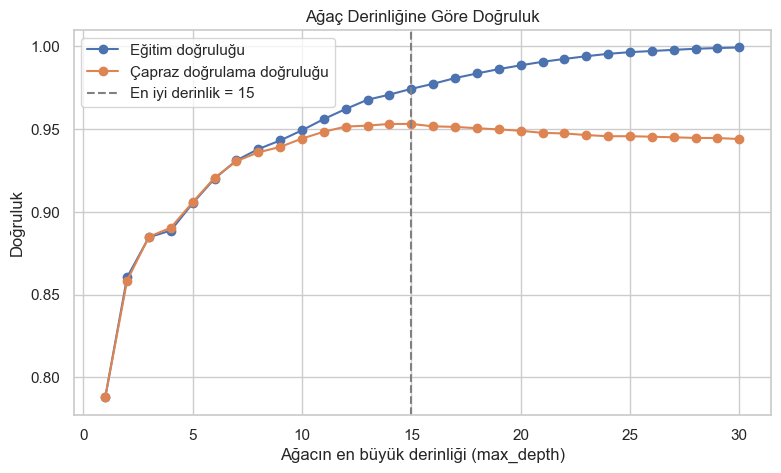

In [26]:
plt.figure(figsize=(9, 5))
plt.plot(derinlikler, egitim_skorlari, marker="o", label="Eğitim doğruluğu")
plt.plot(derinlikler, cv_skorlari, marker="o", label="Çapraz doğrulama doğruluğu")
plt.axvline(en_iyi_derinlik, color="gray", linestyle="--", label=f"En iyi derinlik = {en_iyi_derinlik}")
plt.title("Ağaç Derinliğine Göre Doğruluk")
plt.xlabel("Ağacın en büyük derinliği (max_depth)")
plt.ylabel("Doğruluk")
plt.legend()
plt.show()

**Ne görüyoruz?**
- **Sol taraf (derinlik 1–5):** İki çizgi de düşük. Ağaç çok basit kalıyor (underfitting).
- **Orta (yaklaşık 12–16):** Çapraz doğrulama doğruluğu en yüksek noktasına (yaklaşık **%95,3**) ulaşıyor.
- **Sağ taraf (20 ve üstü):** Eğitim doğruluğu %100'e yaklaşmaya devam ediyor, ama çapraz doğrulama doğruluğu **düşmeye başlıyor**. İki çizginin arasının açılması, overfitting'in görsel işaretidir.

### 4.4 Son karar ağacı modeli
**Ne yapıyoruz?** Bulduğumuz en iyi derinlikle son modeli eğitiyor ve test verisinde deniyoruz. Test tahminlerini `agac_tahmin` adıyla saklıyoruz; Adım 6'da diğer modelle karşılaştırırken kullanacağız.

In [27]:
agac_model = DecisionTreeClassifier(max_depth=en_iyi_derinlik, random_state=42)
agac_model.fit(X_train, y_train)

agac_tahmin = agac_model.predict(X_test)   # test yolcuları için tahminler (0 veya 1)

print(f"Eğitim doğruluğu: %{accuracy_score(y_train, agac_model.predict(X_train)) * 100:.2f}")
print(f"Test doğruluğu  : %{accuracy_score(y_test, agac_tahmin) * 100:.2f}")
print("Yaprak sayısı:", agac_model.get_n_leaves())

Eğitim doğruluğu: %97.44
Test doğruluğu  : %95.53
Yaprak sayısı: 1385


**Ne görüyoruz?** Derinliği sınırlanan ağaç, sınırsız ağaca göre:
- **Test verisinde daha başarılı:** Sınırsız ağaçta %94,7 olan test doğruluğu yaklaşık %95,5'e çıktı.
- **Daha küçük:** Yaprak sayısı yaklaşık 3.900'den 1.400'e indi.
- Eğitim ve test doğrulukları arasındaki fark azaldı, yani ezberleme azaldı.

### 4.5 Karar ağacını görselleştirme
**Ne yapıyoruz?** Ağacın **ilk 3 seviyesini** çiziyoruz. Ağacın tamamı yüzlerce kutudan oluştuğu için okunamaz.

**Kutular nasıl okunur?**
- **1. satır:** Sorulan soru (örneğin `Online boarding <= 3.5` = "Online boarding puanı 3,5 veya daha az mı?"). Cevap **evet** ise **sola**, **hayır** ise **sağa** gidilir.
- **samples:** Bu kutuya ulaşan yolcu sayısı
- **value:** Bu yolculardan kaçının memnun olmadığı ve kaçının memnun olduğu
- **class:** Bu kutuda çoğunlukta olan grup, yani o noktada verilecek tahmin
- **Renk:** Turuncu = çoğunluk memnun değil, mavi = çoğunluk memnun. Renk ne kadar koyuysa grup o kadar "saf".
- **gini:** Kutunun ne kadar karışık olduğunu gösterir. 0 ise kutudaki herkes aynı gruptandır; ağaç her adımda gini'yi en çok düşüren soruyu seçer.

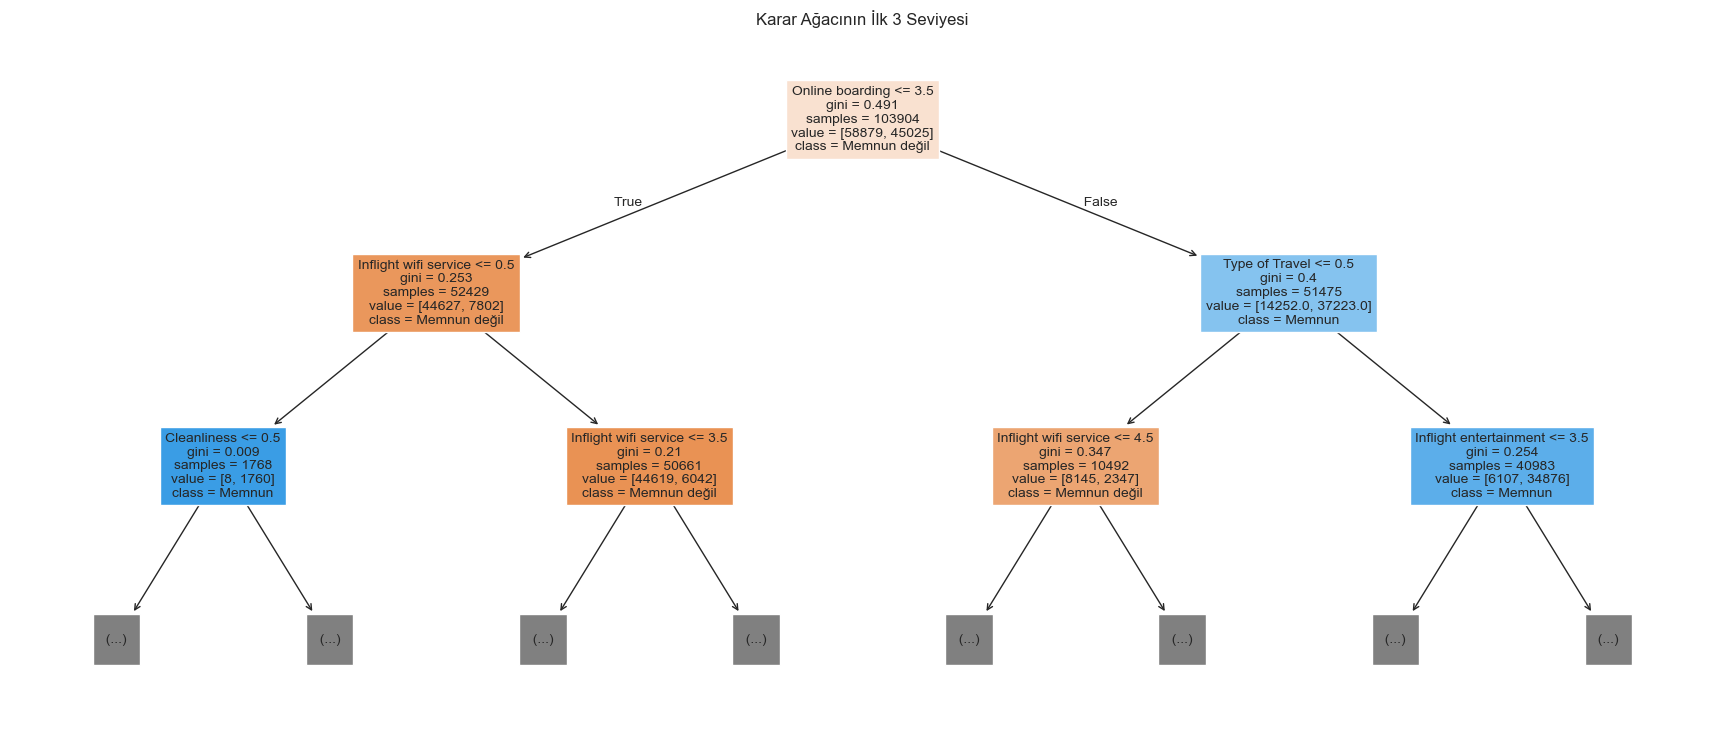

In [28]:
plt.figure(figsize=(22, 9))
plot_tree(agac_model,
          max_depth=2,                                  # sadece ilk 3 seviye (0, 1, 2)
          feature_names=list(X_train.columns),          # soru içinde sütun adları görünsün
          class_names=["Memnun değil", "Memnun"],       # 0 ve 1 yerine anlamlı isimler
          filled=True,                                  # kutuları renklendir
          fontsize=10)
plt.title("Karar Ağacının İlk 3 Seviyesi")
plt.show()

**Ne görüyoruz?**
- Ağacın sorduğu **ilk soru** "Online boarding puanı 3,5 veya daha az mı?". Model, yolcuları ayırmak için en faydalı bilginin bu olduğunu kendisi bulmuş. Bu sonuç, Adım 2'deki analizlerimizle de uyumlu.
- Sonraki sorularda **Inflight wifi service** ve **Type of Travel** gibi sütunlar kullanılıyor.
- Online boarding puanı düşük olanlar (sol taraf) çoğunlukla memnun değil. Puanı yüksek ve **iş amaçlı** seyahat edenler (en sağ) ise büyük çoğunlukla memnun.
- İlginç bir detay: Wifi hizmetine **0** puan veren (yani puan vermeyen) 1.768 yolcunun neredeyse hepsi memnun. Ağaç bu tür ayrıntıları da yakalayabiliyor.
- Karar ağacının en büyük avantajı bu: Hangi kurala göre karar verdiğini **görebiliyor ve açıklayabiliyoruz**.

### Adım 4 Özeti
- Sınırsız bir karar ağacı eğitim verisini ezberledi (overfitting): eğitimde %100, testte %94,7.
- Çapraz doğrulamayla en iyi derinliği seçtik. Sınırlanmış ağaç **testte yaklaşık %95,5** doğruluğa ulaştı.
- Ağacın ilk sorusu **Online boarding** oldu.

## Adım 5: Rastgele Orman (Random Forest)

### 5.1 Rastgele orman nedir?
Adım 4'te gördüğümüz gibi tek bir karar ağacı kolayca **ezberliyor** (overfitting). **Rastgele orman** bu sorunu şöyle çözer: Tek bir ağaç yerine **yüzlerce ağaç** kurar ve bu ağaçların **oylamasıyla** karar verir.

Bir benzetme: Zor bir soruyu tek bir kişiye sormak yerine 100 kişiye sorup çoğunluğun cevabını almak genellikle daha güvenilirdir. Her kişi farklı konularda yanılabilir; ama hataları birbirini götürür ve çoğunluk genellikle doğruyu bulur.

**Ağaçlar neden birbirinden farklı?** İki rastgelelik kaynağı sayesinde:
1. **Rastgele yolcular:** Her ağaç, eğitim verisinden **rastgele seçilmiş** farklı bir yolcu grubuyla eğitilir. (Aynı yolcu birden fazla kez seçilebilir, bazı yolcular hiç seçilmeyebilir. Bu yönteme *bootstrap* denir.)
2. **Rastgele sorular:** Ağaç her soru sorarken bütün sütunlara değil, **rastgele seçilmiş birkaç sütuna** bakar.

Bu sayede her ağaç farklı şeyler öğrenir. Bir yolcu için tahmin yapılırken bütün ağaçlar oy verir ve **çoğunluğun kararı** sonuç olur.

Birden fazla modeli birleştirerek karar veren bu tür yöntemlere **topluluk öğrenmesi** (*ensemble learning*) denir.

In [29]:
from sklearn.ensemble import RandomForestClassifier   # rastgele orman modeli

### 5.2 İlk rastgele orman
**Ne yapıyoruz?** 100 ağaçtan oluşan bir rastgele orman eğitiyoruz ve Adım 4'teki gibi hem eğitim hem test doğruluğuna bakıyoruz.

- `n_estimators=100`: Ormandaki ağaç sayısı
- `n_jobs=-1`: Bilgisayarın bütün işlemci çekirdeklerini kullan, böylece eğitim daha hızlı biter

In [30]:
# 1) Modeli oluştur: 100 ağaçlı orman
orman_ilk = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

# 2) Eğit
orman_ilk.fit(X_train, y_train)

# 3) Doğruluğu hesapla
print(f"Eğitim doğruluğu: %{accuracy_score(y_train, orman_ilk.predict(X_train)) * 100:.2f}")
print(f"Test doğruluğu  : %{accuracy_score(y_test, orman_ilk.predict(X_test)) * 100:.2f}")

Eğitim doğruluğu: %100.00
Test doğruluğu  : %96.24


**Ne görüyoruz?**
- Test doğruluğu yaklaşık **%96,2**. Bu, en iyi karar ağacımızdan (%95,5) daha yüksek; üstelik hiçbir ayar yapmadık.
- Eğitim doğruluğu yine **%100**. Ormandaki her ağaç tek başına ezberliyor olabilir. Ama ağaçlar **farklı hatalar** yaptığı için oylamada bu hatalar birbirini götürüyor; sonuçta orman, yeni yolcularda tek bir ağaçtan daha başarılı oluyor.

### 5.3 Ağaç sayısının etkisi
**Ne yapıyoruz?** Ormandaki ağaç sayısını (`n_estimators`) değiştirip başarının nasıl değiştiğine bakıyoruz. Adım 4'teki gibi seçimi **çapraz doğrulama** ile yapıyoruz ve test verisine dokunmuyoruz.

⏳ Bu hücre yaklaşık **1 dakika** sürebilir; çünkü toplam 5 farklı ormanı 5'er kez eğitiyoruz.

In [31]:
agac_sayilari = [1, 10, 50, 100, 200]
orman_cv_skorlari = []

for n in agac_sayilari:
    model = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)
    skor = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy").mean()
    orman_cv_skorlari.append(skor)
    print(f"{n:>3} ağaç -> çapraz doğrulama doğruluğu: %{skor * 100:.2f}")

en_iyi_agac_sayisi = agac_sayilari[orman_cv_skorlari.index(max(orman_cv_skorlari))]
print("\nEn iyi ağaç sayısı:", en_iyi_agac_sayisi)

  1 ağaç -> çapraz doğrulama doğruluğu: %91.87


 10 ağaç -> çapraz doğrulama doğruluğu: %95.52


 50 ağaç -> çapraz doğrulama doğruluğu: %96.10


100 ağaç -> çapraz doğrulama doğruluğu: %96.14


200 ağaç -> çapraz doğrulama doğruluğu: %96.19

En iyi ağaç sayısı: 200


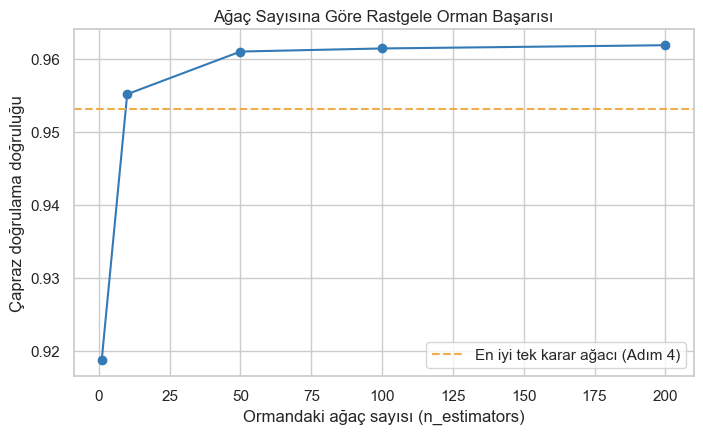

In [32]:
plt.figure(figsize=(8, 4.5))
plt.plot(agac_sayilari, orman_cv_skorlari, marker="o", color="#337ab7")
plt.axhline(max(cv_skorlari), color="#f0ad4e", linestyle="--", label="En iyi tek karar ağacı (Adım 4)")
plt.title("Ağaç Sayısına Göre Rastgele Orman Başarısı")
plt.xlabel("Ormandaki ağaç sayısı (n_estimators)")
plt.ylabel("Çapraz doğrulama doğruluğu")
plt.legend()
plt.show()

**Ne görüyoruz?**
- **1 ağaçlık** orman, en iyi tek karar ağacından bile **daha kötü** (yaklaşık %91,9). Çünkü bu tek ağaç verinin yalnızca rastgele bir kısmını ve rastgele sütunları görüyor.
- Ağaç sayısı **10'a** çıkınca başarı hızla artıyor ve tek karar ağacını geçiyor.
- **50 ağaçtan sonra** başarı neredeyse sabit kalıyor (%96,1–96,2). Daha fazla ağaç eklemek modeli **bozmuyor**, ama eğitim süresini uzatıyor ve neredeyse hiç fayda sağlamıyor.

Bu grafik, rastgele ormanın temel fikrini gösteriyor: **Tek ağaç zayıf, ama çok sayıda ağacın oylaması güçlü.**

### 5.4 Son rastgele orman modeli
**Ne yapıyoruz?** En iyi ağaç sayısıyla son modeli eğitiyor ve test verisinde deniyoruz. Tahminleri `orman_tahmin` adıyla saklıyoruz; Adım 6'da karar ağacıyla karşılaştıracağız.

In [33]:
orman_model = RandomForestClassifier(n_estimators=en_iyi_agac_sayisi, random_state=42, n_jobs=-1)
orman_model.fit(X_train, y_train)

orman_tahmin = orman_model.predict(X_test)   # test yolcuları için tahminler (0 veya 1)

print(f"Eğitim doğruluğu: %{accuracy_score(y_train, orman_model.predict(X_train)) * 100:.2f}")
print(f"Test doğruluğu  : %{accuracy_score(y_test, orman_tahmin) * 100:.2f}")

Eğitim doğruluğu: %100.00
Test doğruluğu  : %96.25


### Adım 5 Özeti
- Rastgele orman, farklı veri parçaları ve farklı sütunlarla eğitilmiş çok sayıda ağacın **oylamasıyla** karar veriyor.
- Test doğruluğu **%96,25** oldu. Bu, karar ağacının ulaştığı **%95,5**'ten daha yüksek.
- Bunun bir bedeli var: Yüzlerce ağaç olduğu için model **daha yavaş** eğitiliyor ve tek bir ağaç gibi çizip **açıklamak mümkün değil**.

Şimdiye kadar yalnızca doğruluğa (accuracy) baktık. Bir sonraki adımda iki modeli **daha ayrıntılı ölçütlerle** karşılaştıracağız.

## Adım 6: Modellerin Karşılaştırılması

Şimdiye kadar yalnızca **doğruluğa** (accuracy) baktık. Ama doğruluk tek başına her şeyi anlatmaz: Model hangi yolcularda hata yapıyor? Memnun yolcuları mı kaçırıyor, yoksa memnun olmayanlara mı yanlışlıkla "memnun" diyor?

Bu soruları cevaplamak için **karışıklık matrisi** ve üç ölçüt daha kullanacağız: **precision**, **recall** ve **F1**.

In [34]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_score, recall_score, f1_score

### 6.1 Karışıklık matrisi (Confusion Matrix)
**Karışıklık matrisi**, modelin tahminlerini gerçek değerlerle karşılaştıran 2×2'lik bir tablodur. Modelin **nerede doğru, nerede yanlış** yaptığını gösterir:

| | Model "memnun değil" dedi | Model "memnun" dedi |
|---|---|---|
| **Gerçekte memnun değil** | ✅ **Doğru Negatif (TN)** | ❌ **Yanlış Pozitif (FP)** |
| **Gerçekte memnun** | ❌ **Yanlış Negatif (FN)** | ✅ **Doğru Pozitif (TP)** |

- **Pozitif** = memnun (1), **negatif** = memnun değil (0)
- **TN (True Negative):** Memnun olmayan yolcuya doğru biçimde "memnun değil" dedi.
- **TP (True Positive):** Memnun yolcuya doğru biçimde "memnun" dedi.
- **FP (False Positive):** Memnun **olmayan** yolcuya yanlışlıkla "memnun" dedi.
- **FN (False Negative):** Memnun **olan** yolcuya yanlışlıkla "memnun değil" dedi.

Köşegendeki (sol üst ve sağ alt) sayılar ne kadar büyükse model o kadar iyidir.

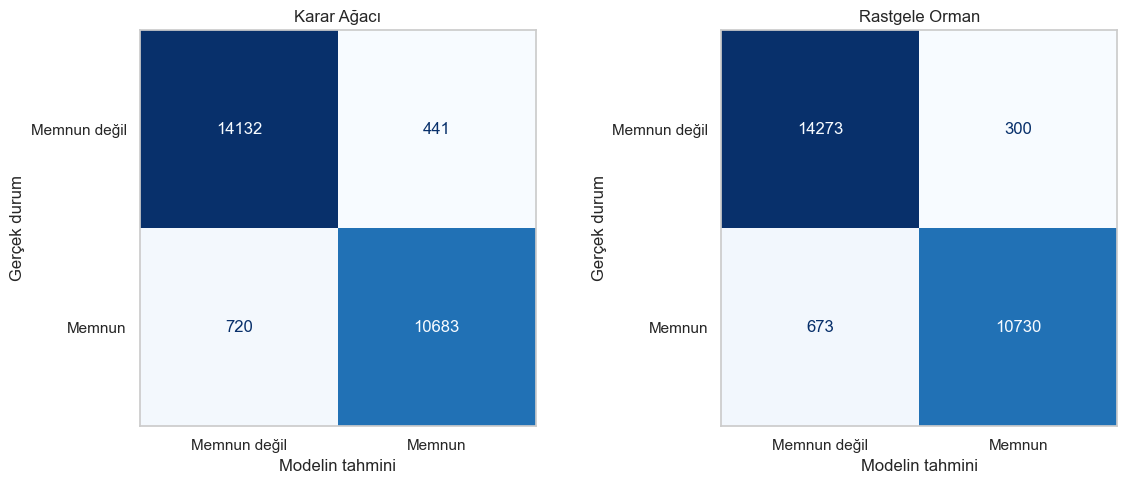

In [35]:
fig, eksenler = plt.subplots(1, 2, figsize=(12, 5))

modeller = [("Karar Ağacı", agac_tahmin), ("Rastgele Orman", orman_tahmin)]

for eksen, (ad, tahmin) in zip(eksenler, modeller):
    matris = confusion_matrix(y_test, tahmin)   # gerçek değerler ile tahminleri karşılaştır
    ConfusionMatrixDisplay(matris, display_labels=["Memnun değil", "Memnun"]).plot(
        ax=eksen, cmap="Blues", values_format="d", colorbar=False)
    eksen.set_title(ad)
    eksen.set_xlabel("Modelin tahmini")
    eksen.set_ylabel("Gerçek durum")
    eksen.grid(False)   # arka plan çizgileri sayıların üstünden geçmesin

plt.tight_layout()
plt.show()

**Ne görüyoruz?** Test verisinde toplam 25.976 yolcu var.

| | Karar Ağacı | Rastgele Orman |
|---|---|---|
| Doğru tahmin (TN + TP) | 24.815 | **25.003** |
| Yanlış "memnun" dedi (FP) | 441 | **300** |
| Memnun yolcuyu kaçırdı (FN) | 720 | **673** |
| **Toplam hata** | 1.161 | **973** |

- Rastgele orman her iki hata türünü de azaltmış; toplam hata sayısı yaklaşık **190 yolcu** daha az.
- İki modelde de **FN, FP'den fazla**. Yani modeller daha çok, memnun olan yolculara "memnun değil" diyerek hata yapıyor.

### 6.2 Precision, Recall ve F1
Karışıklık matrisindeki sayılardan üç önemli ölçüt hesaplanır:

**Precision (Kesinlik):** Modelin **"memnun" dediği** yolcuların yüzde kaçı **gerçekten** memnun?
> Precision = TP / (TP + FP)
> *"Model 'memnun' dediğinde ona ne kadar güvenebilirim?"*

**Recall (Duyarlılık):** **Gerçekten memnun olan** yolcuların yüzde kaçını model **yakalayabildi**?
> Recall = TP / (TP + FN)
> *"Memnun yolcuların ne kadarını bulabildim?"*

**F1 skoru:** Precision ve recall'u **tek bir sayıda** birleştirir (ikisinin *harmonik ortalaması*). İkisinden biri düşükse F1 de düşük çıkar; bu yüzden modelin dengeli olup olmadığını gösterir.
> F1 = 2 × (Precision × Recall) / (Precision + Recall)

**Örnek:** Bir model herkese "memnun" deseydi bütün memnun yolcuları yakalardı (recall = %100), ama "memnun" dediklerinin çoğu aslında memnun olmazdı (precision düşük). F1 bu tür hileli modelleri ortaya çıkarır.

**Ne yapıyoruz?** Dört ölçütü iki model için hesaplayıp bir tabloda topluyoruz. Ayrıca iki modelin **eğitim süresini** de ölçüyoruz; çünkü pratikte hız da önemli bir karşılaştırma ölçütüdür.

In [36]:
import time   # süre ölçmek için

sonuclar = []
for ad, model in [("Karar Ağacı", agac_model), ("Rastgele Orman", orman_model)]:
    baslangic = time.time()
    model.fit(X_train, y_train)          # modeli yeniden eğitip süresini ölçüyoruz
    sure = time.time() - baslangic

    tahmin = model.predict(X_test)
    sonuclar.append({
        "Model": ad,
        "Accuracy": accuracy_score(y_test, tahmin),
        "Precision": precision_score(y_test, tahmin),
        "Recall": recall_score(y_test, tahmin),
        "F1": f1_score(y_test, tahmin),
        "Eğitim süresi (sn)": sure,
    })

sonuc_tablosu = pd.DataFrame(sonuclar).set_index("Model")
sonuc_tablosu.round(4)

,Accuracy,Precision,Recall,F1,Eğitim süresi (sn)
Model,,,,,
Karar Ağacı,0.9553,0.9604,0.9369,0.9485,0.3669
Rastgele Orman,0.9625,0.9728,0.9410,0.9566,3.2371


**Ne yapıyoruz?** Aynı sonuçları grafikle karşılaştırıyoruz. Farklar küçük olduğu için dikey ekseni 0,90'dan başlatıyoruz; aksi halde sütunlar aynı boyda görünürdü.

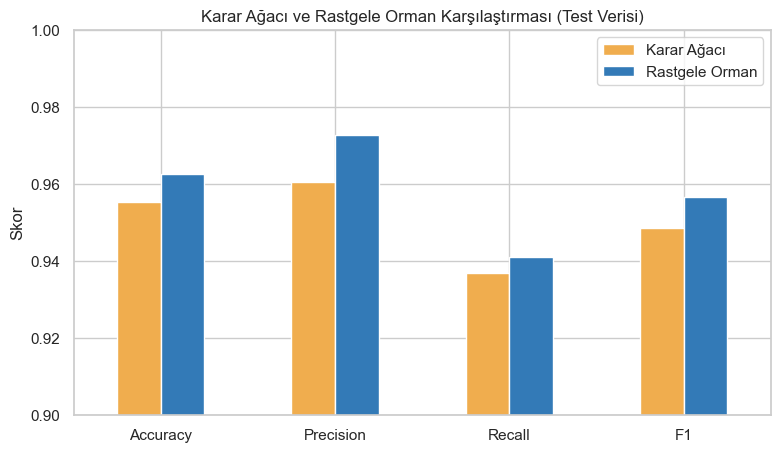

In [37]:
olcutler = ["Accuracy", "Precision", "Recall", "F1"]

sonuc_tablosu[olcutler].T.plot(kind="bar", figsize=(9, 5), color=["#f0ad4e", "#337ab7"])
plt.ylim(0.90, 1.00)   # farkları görebilmek için ekseni 0.90'dan başlatıyoruz
plt.title("Karar Ağacı ve Rastgele Orman Karşılaştırması (Test Verisi)")
plt.ylabel("Skor")
plt.xticks(rotation=0)
plt.legend(title="")
plt.show()

**Ne görüyoruz?**

| Ölçüt | Karar Ağacı | Rastgele Orman |
|---|---|---|
| Accuracy | %95,5 | **%96,3** |
| Precision | %96,0 | **%97,3** |
| Recall | %93,7 | **%94,1** |
| F1 | %94,9 | **%95,7** |

- Rastgele orman **dört ölçütün hepsinde** karar ağacından daha iyi.
- En büyük fark **precision**'da: Rastgele orman "memnun" dediğinde %97,3 oranında haklı çıkıyor.
- İki modelde de recall, precision'dan biraz düşük. Bu sonuç, 6.1'de gördüğümüz FN > FP durumuyla tutarlı.
- **Eğitim süresi:** Rastgele orman, karar ağacından **birkaç kat daha uzun** sürede eğitiliyor (süreler bilgisayara göre değişir).

### 6.3 Genel karşılaştırma ve yorum

| | Karar Ağacı | Rastgele Orman |
|---|---|---|
| **Başarı** | Yüksek (%95,5) | **Daha yüksek (%96,3)** |
| **Overfitting'e dayanıklılık** | Düşük; derinliği sınırlamak gerekti | **Yüksek**; ayar yapmadan bile iyi sonuç verdi |
| **Hız** | **Çok hızlı** | Daha yavaş (yüzlerce ağaç) |
| **Açıklanabilirlik** | **Kolay**; ağaç çizilip kurallar okunabiliyor | Zor; yüzlerce ağacı tek tek incelemek mümkün değil |

**Sonuç:** Amaç **en doğru tahmin** ise rastgele orman daha iyi bir seçim. Amaç, havayolu yöneticilerine "yolcular neden memnun değil?" sorusunu **basit kurallarla anlatmak** ise karar ağacı daha kullanışlı. İki model arasındaki başarı farkı (yaklaşık 0,7 puan) küçük, ama yaklaşık 26.000 yolcudan oluşan test verisinde yaklaşık **190 yolcunun daha doğru tahmin edilmesi** demek.

## Adım 7: Özellik Önemi (Feature Importance)

### 7.1 Özellik önemi nedir?
**Özellik önemi** (*feature importance*), modelin tahmin yaparken **hangi bilgilere ne kadar dayandığını** gösteren bir puandır.

Karar ağacında her soru, yolcuları memnun ve memnun olmayan olarak biraz daha iyi ayırır (Adım 4'teki **gini** değerini düşürür). Bir özellik ağaçta ne kadar sık ve ne kadar etkili sorularda kullanılmışsa, önem puanı o kadar yüksek olur. Rastgele ormanda bu puan bütün ağaçların ortalaması alınarak hesaplanır.

Bütün özelliklerin önem puanlarının toplamı **1**'dir. Bu yüzden her puanı bir **yüzde** gibi okuyabiliriz. Örneğin 0,30 = "modelin kararlarındaki etkinin %30'u bu özellikten geliyor".

**Neden önemli?** Model yalnızca tahmin yapmakla kalmıyor, aynı zamanda **"yolcu memnuniyetini en çok ne etkiliyor?"** sorusuna da cevap veriyor. Bu bilgi bir havayolu şirketi için tahminin kendisinden bile daha değerli olabilir.

### 7.2 İki modelin özellik önemlerini hesaplama
**Ne yapıyoruz?** Eğitilmiş modellerin `feature_importances_` özelliğinden önem puanlarını alıp bir tabloya koyuyoruz.

In [38]:
onem = pd.DataFrame({
    "Karar Ağacı": agac_model.feature_importances_,
    "Rastgele Orman": orman_model.feature_importances_,
}, index=X_train.columns)                      # satır adları = özellik adları

onem = onem.sort_values("Rastgele Orman", ascending=False)   # en önemliden en önemsize sırala
onem.round(3)

,Karar Ağacı,Rastgele Orman
Online boarding,0.391,0.167
Inflight wifi service,0.192,0.143
Type of Travel,0.159,0.087
Class_Business,0.022,0.080
Inflight entertainment,0.050,0.057
Seat comfort,0.013,0.046
Class_Eco,0.000,0.041
Leg room service,0.008,0.038
Ease of Online booking,0.002,0.038
Flight Distance,0.009,0.034


### 7.3 Grafikle gösterme
**Ne yapıyoruz?** Önem puanlarını yatay bir sütun grafikte gösteriyoruz. En önemli özellikler en üstte yer alıyor.

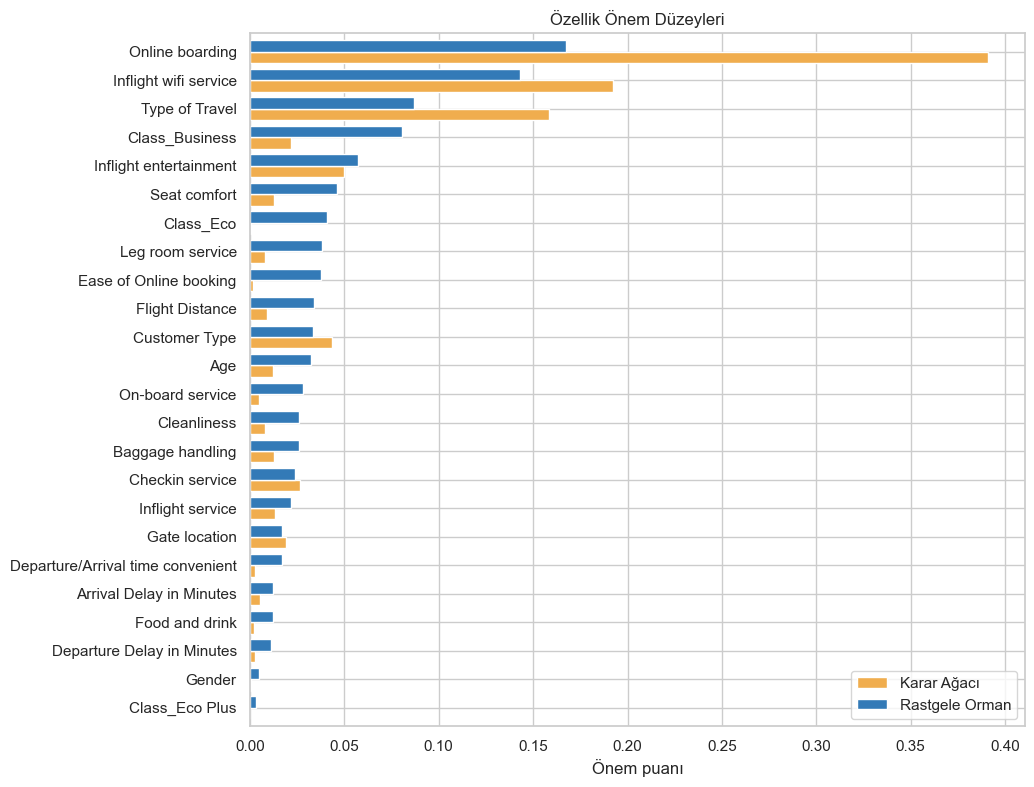

In [39]:
onem.sort_values("Rastgele Orman").plot(   # grafikte en önemli en üstte görünsün diye ters sıralıyoruz
    kind="barh", figsize=(10, 9), color=["#f0ad4e", "#337ab7"], width=0.8)
plt.title("Özellik Önem Düzeyleri")
plt.xlabel("Önem puanı")
plt.legend(title="", loc="lower right")
plt.show()

**Ne görüyoruz?**

**İki model de aynı üç özelliği en üstte görüyor:**
1. **Online boarding** (çevrimiçi biniş): İki modelde de **en önemli** özellik. Karar ağacının kararlarının yaklaşık **%39'u**, rastgele ormanın ise **%17'si** bu özellikten geliyor.
2. **Inflight wifi service** (uçak içi wifi)
3. **Type of Travel** (iş / kişisel seyahat)

Bunları **Class_Business** (Business sınıfı), **Inflight entertainment** (uçak içi eğlence) ve **Seat comfort** (koltuk konforu) izliyor.

**En önemsiz özellikler:** **Gender** (cinsiyet), **gecikme süreleri**, **Food and drink** (yiyecek-içecek) ve **Class_Eco Plus**.

**İki model arasındaki fark:**
- **Karar ağacı** önemi birkaç özellikte **topluyor**: İlk üç özellik toplam önemin yaklaşık **%74'ünü** oluşturuyor.
- **Rastgele orman** önemi daha **dengeli dağıtıyor**. Çünkü her ağaç her soruda yalnızca rastgele seçilmiş birkaç sütuna bakıyor (Adım 5). Online boarding o ağacın seçtiği sütunlar arasında yoksa ağaç başka bir özellik kullanmak zorunda kalıyor; böylece daha fazla özellik söz sahibi oluyor.

### 7.4 Adım 2'deki tahminlerimiz doğru çıktı mı?

| Adım 2'deki bulgu | Model sonucu |
|---|---|
| Online boarding memnuniyetle en ilişkili özellik | ✅ **Doğru**: İki modelde de 1. sırada |
| Seyahat tipi ve uçuş sınıfı çok etkili | ✅ **Doğru**: Rastgele ormanda ilk 4 içinde |
| Cinsiyetin etkisi yok | ✅ **Doğru**: En önemsiz özelliklerden biri |
| Gecikmelerin etkisi zayıf | ✅ **Doğru**: Alt sıralarda |
| Wifi korelasyonu orta düzeyde (0,28) | ❓ **Sürpriz**: Modelde **2. sırada** |

Wifi'nin korelasyonu orta düzeyde olduğu halde model neden onu bu kadar önemli buldu? Gelin bakalım.

### 7.5 Wifi neden bu kadar önemli?
**Ne yapıyoruz?** Wifi'ye verilen her puan için yolcuların yüzde kaçının memnun olduğunu hesaplayıp çiziyoruz.

Inflight wifi service
0    99.7
1    32.5
2    24.9
3    25.1
4    59.9
5    99.1
Name: satisfaction, dtype: float64


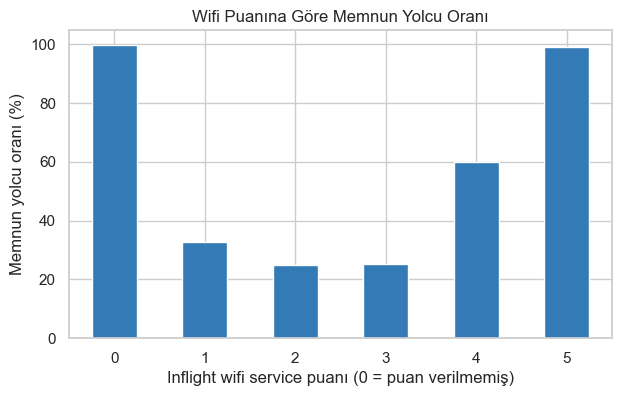

In [40]:
# Her wifi puanı için memnun yolcuların yüzdesi
wifi_oran = train.groupby("Inflight wifi service")["satisfaction"].apply(
    lambda s: (s == "satisfied").mean() * 100)
print(wifi_oran.round(1))

wifi_oran.plot(kind="bar", color="#337ab7", figsize=(7, 4))
plt.title("Wifi Puanına Göre Memnun Yolcu Oranı")
plt.xlabel("Inflight wifi service puanı (0 = puan verilmemiş)")
plt.ylabel("Memnun yolcu oranı (%)")
plt.xticks(rotation=0)
plt.show()

**Ne görüyoruz?** İlişki **düz bir çizgi** gibi değil, **U harfi** şeklinde:
- Wifi'ye **0** (puan vermemiş) veya **5** veren yolcuların **neredeyse tamamı (%99)** memnun.
- **1, 2 veya 3** verenlerin yalnızca **%25–33'ü** memnun.
- **4** verenlerin yaklaşık **%60'ı** memnun.

**Korelasyon** yalnızca "biri artınca öteki de düzenli olarak artıyor mu?" sorusuna bakar. Bu U şeklindeki ilişkiyi tam olarak yakalayamaz ve bu yüzden düşük çıkar. **Karar ağacı** ise "wifi puanı 0 mı?", "wifi puanı 4'ten büyük mü?" gibi sorular sorarak bu ilişkiyi kolayca yakalar. (Adım 4'teki ağaç çiziminde "Inflight wifi service <= 0.5" sorusunu hatırla.)

Bu örnek, makine öğrenmesi modellerinin basit istatistiklerin kaçırdığı **karmaşık ilişkileri** bulabildiğini gösteriyor.

### 7.6 Havayolu şirketi için ne anlama geliyor?
Model sonuçlarına göre havayolu şirketi memnuniyeti artırmak için öncelikle şunlara odaklanmalı:
1. **Dijital hizmetler:** **Online biniş** sistemini ve **uçak içi wifi** hizmetini iyileştirmek en etkili adım görünüyor.
2. **Kişisel seyahat eden ve Eco sınıfı yolcular:** Bu yolcular en az memnun olan grup. Onlara yönelik iyileştirmeler büyük fark yaratabilir.
3. **Konfor:** Uçak içi eğlence ve koltuk konforu da önemli rol oynuyor.

Cinsiyet, kapı konumu ve yiyecek-içecek gibi konuların ise memnuniyete etkisi düşük.

**Dikkat:** Özellik önemi, bir özelliğin modelin tahmininde ne kadar **işe yaradığını** gösterir; **neden-sonuç** ilişkisi kanıtlamaz. Örneğin "wifi'yi iyileştirirsek yolcular kesinlikle memnun olur" diyemeyiz; ama bunun denemeye değer bir öncelik olduğunu söyleyebiliriz.

### Adım 7 Özeti
- Memnuniyeti tahmin etmede en önemli üç özellik **Online boarding**, **Inflight wifi service** ve **Type of Travel**.
- Cinsiyet ve gecikmelerin etkisi çok düşük.
- Model sonuçları, Adım 2'deki analizlerimizle büyük ölçüde uyumlu. Model ayrıca wifi ile memnuniyet arasındaki **U şeklindeki ilişkiyi** de keşfetti; korelasyon bu ilişkiyi yakalayamamıştı.

## Adım 8: Sonuç ve Değerlendirme

### 8.1 Projenin özeti

**Amaç:** Havayolu yolcularının demografik bilgileri, uçuş bilgileri ve hizmet puanlarından yola çıkarak memnun olup olmadıklarını tahmin etmek.

**Veri seti:** Kaggle *Airline Passenger Satisfaction*: 103.904 eğitim ve 25.976 test yolcusu, 22 özellik ve 1 hedef değişken. Veri dengeli (%57 memnun değil, %43 memnun).

**Yapılan adımlar:**
1. **Veri tanıtımı ve keşifsel analiz:** Seyahat tipi, uçuş sınıfı ve online biniş puanının memnuniyetle güçlü ilişkisi olduğu görüldü.
2. **Ön işleme:** Sıra numarası sütunları atıldı; 393 eksik varış gecikmesi değeri eğitim verisinin medyanıyla dolduruldu; yazı halindeki sütunlar 0/1 ve one-hot encoding ile sayıya çevrildi.
3. **Karar ağacı:** Sınırsız ağacın ezberlediği (overfitting) görüldü; çapraz doğrulama ile en iyi derinlik **15** olarak seçildi.
4. **Rastgele orman:** Çapraz doğrulama ile en iyi ağaç sayısı **200** olarak seçildi.
5. **Değerlendirme:** İki model test verisinde accuracy, precision, recall, F1 ve karışıklık matrisiyle karşılaştırıldı.
6. **Özellik önemi:** Memnuniyeti en çok etkileyen özellikler belirlendi.

**Sonuçlar (test verisi):**

| Ölçüt | Karar Ağacı | Rastgele Orman |
|---|---|---|
| Accuracy | %95,5 | **%96,3** |
| Precision | %96,0 | **%97,3** |
| Recall | %93,7 | **%94,1** |
| F1 | %94,9 | **%95,7** |
| Toplam hatalı tahmin | 1.161 | **973** |
| Eğitim süresi | **Çok kısa** | Birkaç kat daha uzun |
| Açıklanabilirlik | **Kolay** (ağaç çizilebiliyor) | Zor |

### 8.2 Yorum
- **Rastgele orman tüm ölçütlerde daha başarılıdır.** Çok sayıda farklı ağacın oylamasıyla karar verdiği için tek bir ağacın ezberleme eğilimini azaltır.
- **Karar ağacı** biraz daha düşük başarıya rağmen **çok hızlıdır** ve **kurallarını okuyabildiğimiz** için yöneticilere sonuçları açıklamakta daha kullanışlıdır.
- Memnuniyeti en çok belirleyen özellikler **Online boarding**, **Inflight wifi service** ve **Type of Travel**'dır. **Cinsiyet** ve **gecikmelerin** etkisi oldukça düşüktür.
- Wifi ile memnuniyet arasındaki **U şeklindeki ilişki**, korelasyon analizinde gözden kaçmış, ağaç tabanlı modeller tarafından yakalanmıştır.
- **Havayolu şirketi için öneri:** Dijital hizmetlerin (online biniş, wifi) iyileştirilmesi ve özellikle kişisel seyahat eden ve Eco sınıfı yolculara odaklanılması.

### 8.3 Sınırlılıklar ve geliştirme önerileri
- Hiperparametre aramasında yalnızca birer ayar denendi (karar ağacında derinlik, rastgele ormanda ağaç sayısı). Daha fazla ayarın birlikte denenmesi (örneğin `GridSearchCV` ile) sonuçları biraz iyileştirebilir.
- Gradient Boosting veya XGBoost gibi daha gelişmiş topluluk yöntemleri de denenebilir.
- Veri seti tek bir kaynaktan geliyor ve anket verisine dayanıyor; hangi havayoluna ve hangi yıllara ait olduğu belirtilmemiş. Sonuçlar başka havayollarına doğrudan genellenemeyebilir.
- Özellik önemi neden-sonuç ilişkisi göstermez; hizmet iyileştirmelerinin gerçek etkisi ancak uygulamada ölçülebilir.

## Kaynaklar
1. Klein, T. J. *Airline Passenger Satisfaction* [Veri seti]. Kaggle. https://www.kaggle.com/datasets/teejmahal20/airline-passenger-satisfaction
2. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5–32. https://doi.org/10.1023/A:1010933404324
3. Breiman, L., Friedman, J. H., Olshen, R. A., & Stone, C. J. (1984). *Classification and Regression Trees*. Wadsworth. https://doi.org/10.1201/9781315139470
4. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html
5. scikit-learn geliştiricileri. *Decision Trees* ve *Ensemble methods* (Kullanım kılavuzu). https://scikit-learn.org/stable/modules/tree.html ve https://scikit-learn.org/stable/modules/ensemble.html#forest
